In [1]:

# Install the dataset library
!pip install -q ucimlrepo

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch the UCI Online Retail dataset
from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)

# Load the original dataset
df = online_retail.data.original.copy()

print("E-Commerce Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


E-Commerce Dataset Loaded Successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268

Statistical Summary:


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000



Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [3]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Convert columns to correct data types
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'], errors='coerce'
)

df_clean['Quantity'] = pd.to_numeric(
    df_clean['Quantity'], errors='coerce'
)

df_clean['UnitPrice'] = pd.to_numeric(
    df_clean['UnitPrice'], errors='coerce'
)

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
].copy()

# Remove invalid quantities and prices
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

# Remove rows with missing essential information
df_clean = df_clean.dropna(
    subset=['InvoiceNo', 'StockCode', 'Description',
            'InvoiceDate', 'Quantity', 'UnitPrice', 'Country']
)

print("Data cleaning completed!")
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Records:", df_clean.duplicated().sum())

display(df_clean.head())


Data cleaning completed!
Original Shape: (541909, 8)
Cleaned Shape: (524878, 8)

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64

Duplicate Records: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:

# Calculate revenue
df_clean['Revenue'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

# Extract date and time information
df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month'] = df_clean['InvoiceDate'].dt.month_name()
df_clean['Month_Number'] = df_clean['InvoiceDate'].dt.month
df_clean['Day'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

print("New columns created successfully!")

display(
    df_clean[['InvoiceDate', 'Quantity', 'UnitPrice',
              'Revenue', 'Month', 'Day', 'Hour']].head()
)


New columns created successfully!


,InvoiceDate,Quantity,UnitPrice,Revenue,Month,Day,Hour
0,2010-12-01 08:26:00,6,2.55,15.30,December,Wednesday,8
1,2010-12-01 08:26:00,6,3.39,20.34,December,Wednesday,8
2,2010-12-01 08:26:00,8,2.75,22.00,December,Wednesday,8
3,2010-12-01 08:26:00,6,3.39,20.34,December,Wednesday,8
4,2010-12-01 08:26:00,6,3.39,20.34,December,Wednesday,8


In [5]:

total_revenue = df_clean['Revenue'].sum()
total_orders = df_clean['InvoiceNo'].nunique()
total_customers = df_clean['CustomerID'].nunique()
total_products = df_clean['StockCode'].nunique()
total_quantity = df_clean['Quantity'].sum()
average_order_value = total_revenue / total_orders

print("E-COMMERCE SALES KPI REPORT")
print("-" * 40)

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Total Items Sold: {total_quantity:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")


E-COMMERCE SALES KPI REPORT
----------------------------------------
Total Revenue: £10,642,110.80
Total Orders: 19,960
Total Customers: 4,338
Unique Products: 3,922
Total Items Sold: 5,572,420
Average Order Value: £533.17


Monthly Revenue:
Jan     689811.610
Feb     522545.560
Mar     716215.260
Apr     536968.491
May     769296.610
Jun     760547.010
Jul     718076.121
Aug     757841.380
Sep    1056435.192
Oct    1151263.730
Nov    1503866.780
Dec    1459243.060
Name: Revenue, dtype: float64


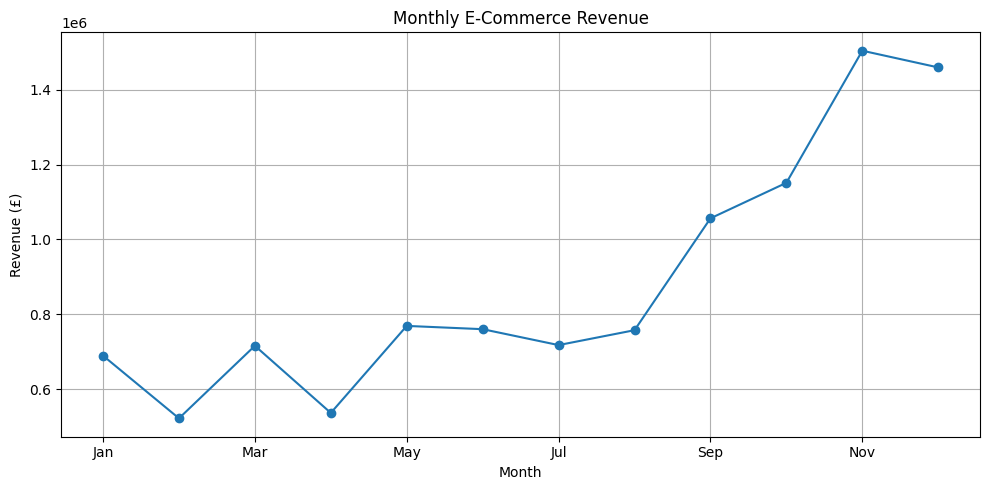

In [6]:

monthly_sales = (
    df_clean.groupby('Month_Number')['Revenue']
    .sum()
    .sort_index()
)

month_labels = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_sales.index = [
    month_labels[int(month)-1]
    for month in monthly_sales.index
]

print("Monthly Revenue:")
print(monthly_sales)

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly E-Commerce Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.grid(True)
plt.tight_layout()
plt.show()


Top 10 Best-Selling Products:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


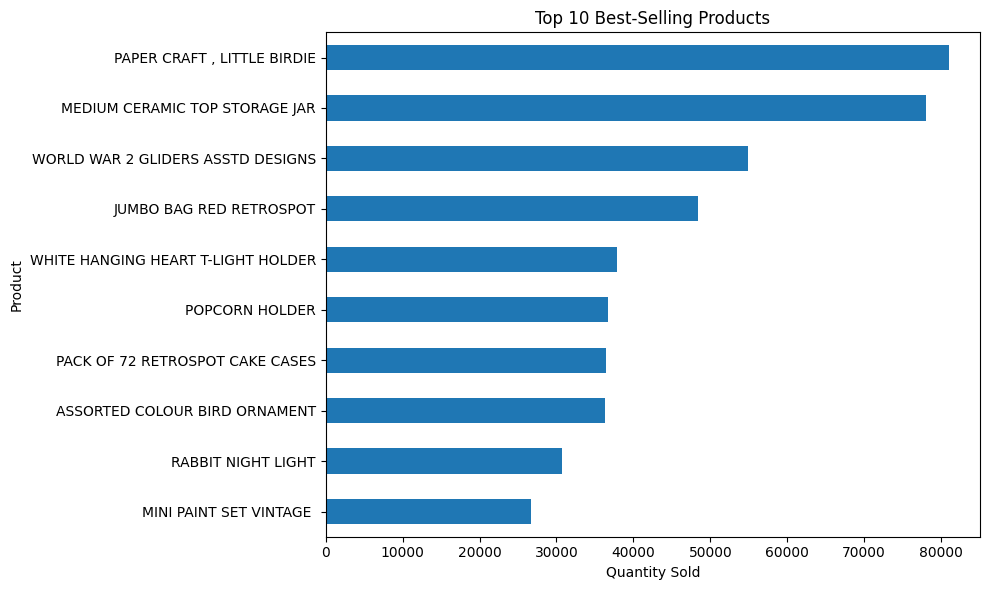

In [7]:

top_products = (
    df_clean.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Best-Selling Products:")
print(top_products)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind='barh')
plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()


Top 10 Countries by Revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


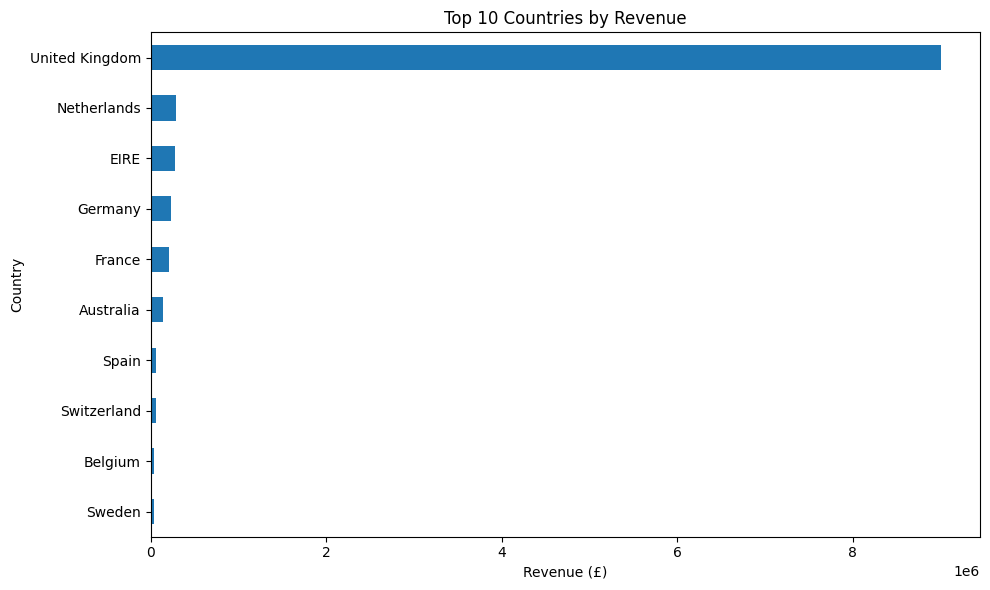

In [8]:

country_sales = (
    df_clean.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Countries by Revenue:")
print(country_sales)

plt.figure(figsize=(10, 6))
country_sales.sort_values().plot(kind='barh')
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


Top 10 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


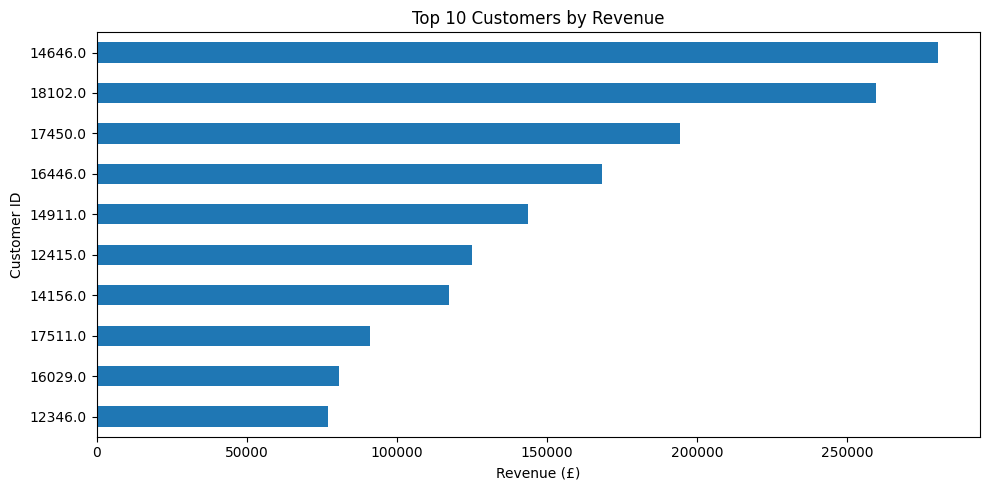

In [9]:

customer_df = df_clean.dropna(subset=['CustomerID']).copy()

customer_sales = (
    customer_df.groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Revenue:")
print(customer_sales.head(10))

plt.figure(figsize=(10, 5))
customer_sales.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()


Daily Revenue:
Day
Monday       1775782.071
Tuesday      2175700.511
Wednesday    1847074.380
Thursday     2199292.570
Friday       1837470.491
Saturday             NaN
Sunday        806790.781
Name: Revenue, dtype: float64


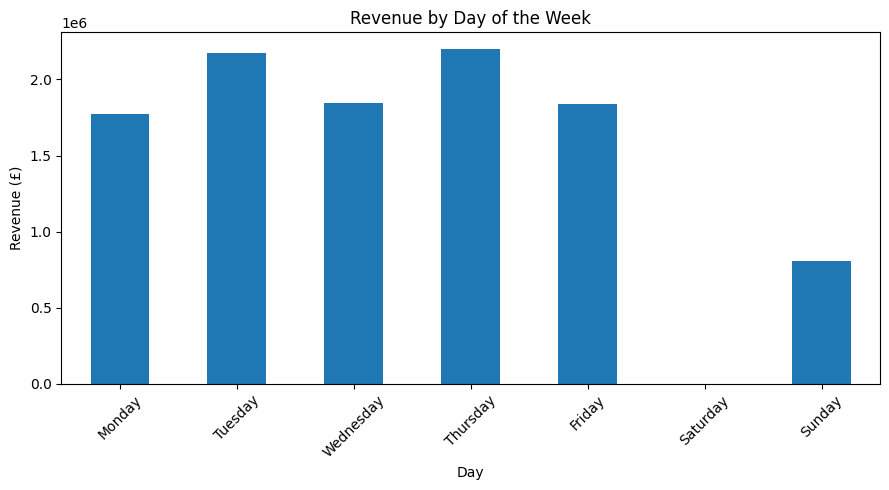

In [10]:

daily_sales = df_clean.groupby('Day')['Revenue'].sum()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = daily_sales.reindex(day_order)

print("Daily Revenue:")
print(daily_sales)

plt.figure(figsize=(9, 5))
daily_sales.plot(kind='bar')
plt.title('Revenue by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Hourly Revenue:
Hour
6           4.250
7       31059.210
8      283750.680
9      990054.991
10    1444814.771
11    1236573.290
12    1439324.660
13    1261195.200
14    1177907.521
15    1350333.310
16     752487.960
17     460963.921
18     144603.610
19      50204.950
20      18832.480
Name: Revenue, dtype: float64


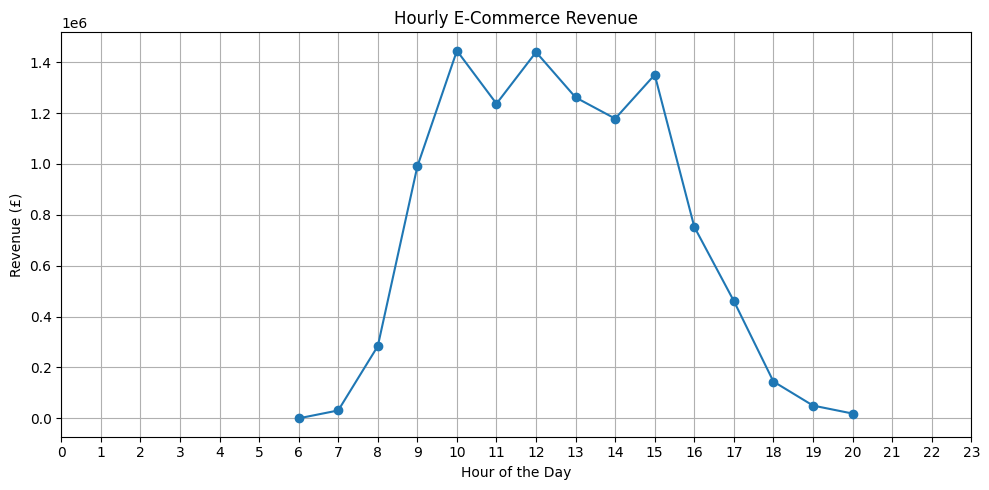

In [11]:

hourly_sales = df_clean.groupby('Hour')['Revenue'].sum()

print("Hourly Revenue:")
print(hourly_sales)

plt.figure(figsize=(10, 5))
hourly_sales.plot(kind='line', marker='o')
plt.title('Hourly E-Commerce Revenue')
plt.xlabel('Hour of the Day')
plt.ylabel('Revenue (£)')
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()


Top 10 Products by Revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


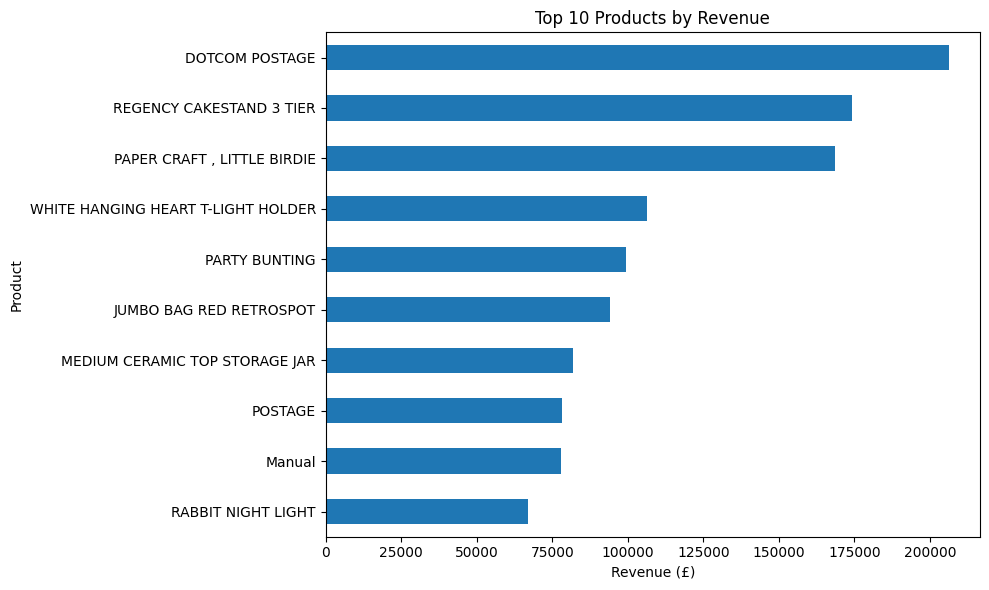

In [12]:

top_revenue_products = (
    df_clean.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
print(top_revenue_products)

plt.figure(figsize=(10, 6))
top_revenue_products.sort_values().plot(kind='barh')
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()


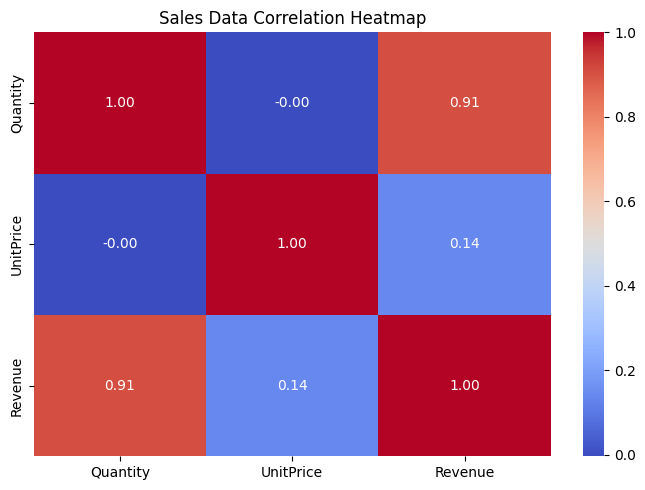

Correlation Results:
           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.003788  0.907402
UnitPrice -0.003788   1.000000  0.137381
Revenue    0.907402   0.137381  1.000000


In [13]:

numeric_columns = [
    'Quantity', 'UnitPrice', 'Revenue'
]

correlation = df_clean[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Sales Data Correlation Heatmap')
plt.tight_layout()
plt.show()

print("Correlation Results:")
print(correlation)


In [14]:

top_country = df_clean.groupby('Country')['Revenue'].sum().idxmax()

top_product = (
    df_clean.groupby('Description')['Quantity']
    .sum().idxmax()
)

top_revenue_product = (
    df_clean.groupby('Description')['Revenue']
    .sum().idxmax()
)

best_month = (
    df_clean.groupby('Month_Number')['Revenue']
    .sum().idxmax()
)

best_day = daily_sales.idxmax()
best_hour = hourly_sales.idxmax()

print("E-COMMERCE SALES ANALYSIS - KEY FINDINGS")
print("-" * 45)

print("Highest Revenue Country:", top_country)
print("Best-Selling Product:", top_product)
print("Highest Revenue Product:", top_revenue_product)
print("Best Performing Month:", month_labels[best_month - 1])
print("Highest Revenue Day:", best_day)
print("Highest Revenue Hour:", best_hour)

print(f"\nTotal Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")


E-COMMERCE SALES ANALYSIS - KEY FINDINGS
---------------------------------------------
Highest Revenue Country: United Kingdom
Best-Selling Product: PAPER CRAFT , LITTLE BIRDIE
Highest Revenue Product: DOTCOM POSTAGE
Best Performing Month: Nov
Highest Revenue Day: Thursday
Highest Revenue Hour: 10

Total Revenue: £10,642,110.80
Total Orders: 19,960
Total Customers: 4,338


In [15]:

# Save cleaned dataset
df_clean.to_csv('cleaned_ecommerce_sales.csv', index=False)

# Save analysis summaries
monthly_sales.to_csv('monthly_sales_summary.csv')
top_products.to_csv('top_selling_products.csv')
country_sales.to_csv('country_sales_summary.csv')
customer_sales.head(10).to_csv('top_customers_summary.csv')
daily_sales.to_csv('daily_sales_summary.csv')
hourly_sales.to_csv('hourly_sales_summary.csv')
top_revenue_products.to_csv('top_revenue_products.csv')
correlation.to_csv('sales_correlation_results.csv')

print("All project files saved successfully!")


All project files saved successfully!


In [16]:

from google.colab import files

files.download('cleaned_ecommerce_sales.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>